<a href="https://colab.research.google.com/github/varshayinithangaraju30-lgtm/customer-segmentation-kmeans/blob/main/visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Variance explained by PC1, PC2: [0.563 0.341]
Total: 0.904


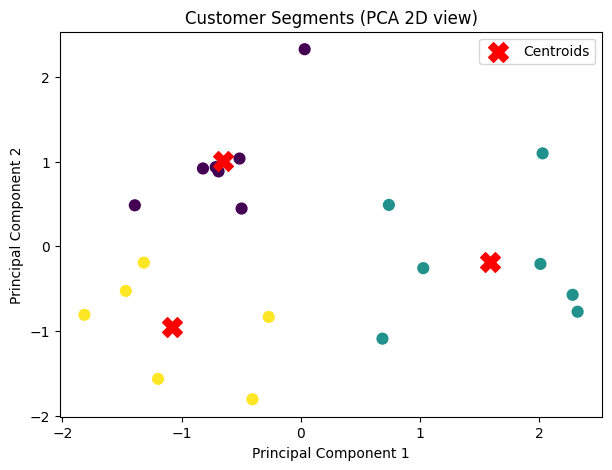

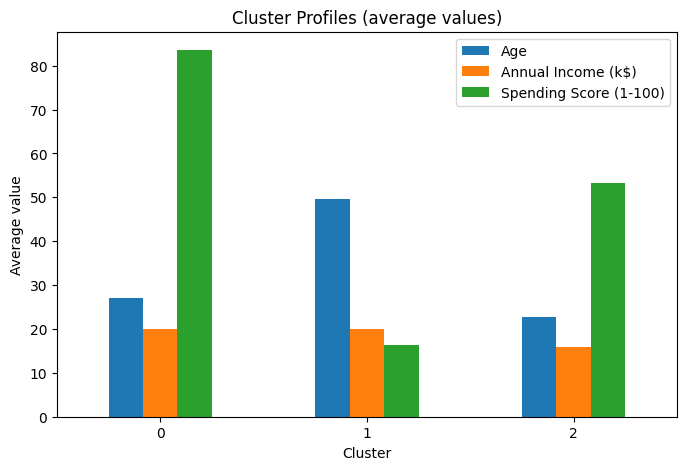

          Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                  
0        27.0                20.0                    83.6
1        49.7                20.0                    16.4
2        22.7                16.0                    53.2


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

URL = "https://raw.githubusercontent.com/varshayinithangaraju30-lgtm/customer-segmentation-kmeans/main/Mall_Customers.csv"
FEATURES = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]

def load_and_scale(path):
    df = pd.read_csv(path)
    if df.empty:
        raise ValueError("Input data is empty")
    df = df.drop_duplicates().dropna(subset=FEATURES)
    X = StandardScaler().fit_transform(df[FEATURES])
    return df, X

def reduce_to_2d(X):
    """Reduce features to 2 dimensions using PCA."""
    if X.shape[1] < 2:
        raise ValueError("Need at least 2 features for PCA")
    pca = PCA(n_components=2, random_state=42)
    X_2d = pca.fit_transform(X)
    return X_2d, pca

df, X = load_and_scale(URL)

# Cluster
K = 3
model = KMeans(n_clusters=K, init="k-means++", n_init=10, random_state=42)
df["Cluster"] = model.fit_predict(X)

# PCA to 2D
X_2d, pca = reduce_to_2d(X)
centers_2d = pca.transform(model.cluster_centers_)

print("Variance explained by PC1, PC2:", pca.explained_variance_ratio_.round(3))
print("Total:", round(pca.explained_variance_ratio_.sum(), 3))

# Plot 1: Clusters in PCA space
plt.figure(figsize=(7, 5))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=df["Cluster"], cmap="viridis", s=60)
plt.scatter(centers_2d[:, 0], centers_2d[:, 1], c="red", marker="X", s=200, label="Centroids")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segments (PCA 2D view)")
plt.legend()
plt.show()

# Plot 2: Average of each feature per cluster
profile = df.groupby("Cluster")[FEATURES].mean()
profile.plot(kind="bar", figsize=(8, 5))
plt.title("Cluster Profiles (average values)")
plt.ylabel("Average value")
plt.xticks(rotation=0)
plt.show()

print(profile.round(1))